##### <center>Beyond global density in a stochastic sandpile: the role of spatial signatures in the predictability of extremes</center>
<center>K.P. Orzechowski, J. Sienkiewicz & P. Fronczak</center> <br>
<center>Workbook 6: Variables</center>

---

Two macroscopic variables against the network. The model and the alarm thresholds come from the training set, the numbers from the test set.

---

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, "../data_management")
import M6_Variables as m

pd.set_option("display.max_columns", None)
SIZES = (32, 64, 128)

COLORS = {32: "darkgoldenrod", 64: "darkred", 128: "darkgreen"}
BG, TEXT, LABEL, GRAY, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams["pdf.fonttype"] = 42

#### The two-variable model (q, R2) (Table 6)

In [2]:
model = {L: m.two_variable_model(L) for L in SIZES}
m.table(model)

,model.b0,model.bq,model.bR,model.mean,model.std,auc.auc_q,auc.auc_R2,auc.auc_qR2,auc.delta_auc,auc.ci_delta_auc,auc.n_boot,eps.q.threshold,eps.q.eps,eps.qR2.threshold,eps.qR2.eps,eps.delta_eps
32,-0.984654,4.677360,2.508810,"[0.6984, 0.00443]","[0.01559, 0.003545]",0.953757,0.825981,0.985419,0.031662,"[0.02943, 0.03387]",2000,0.700195,0.227945,-0.243231,0.118207,-0.109737
64,-5.024803,4.831903,2.366935,"[0.7022, 0.001156]","[0.006494, 0.0008342]",0.967191,0.851745,0.992955,0.025765,"[0.02323, 0.02844]",2000,0.705811,0.190678,-1.707701,0.075436,-0.115242
128,-7.158901,4.403941,2.515325,"[0.7079, 0.0003453]","[0.002585, 0.0001962]",0.973590,0.856476,0.996098,0.022508,"[0.01947, 0.02599]",2000,0.709900,0.170302,-2.077909,0.058918,-0.111384


#### Figure 4

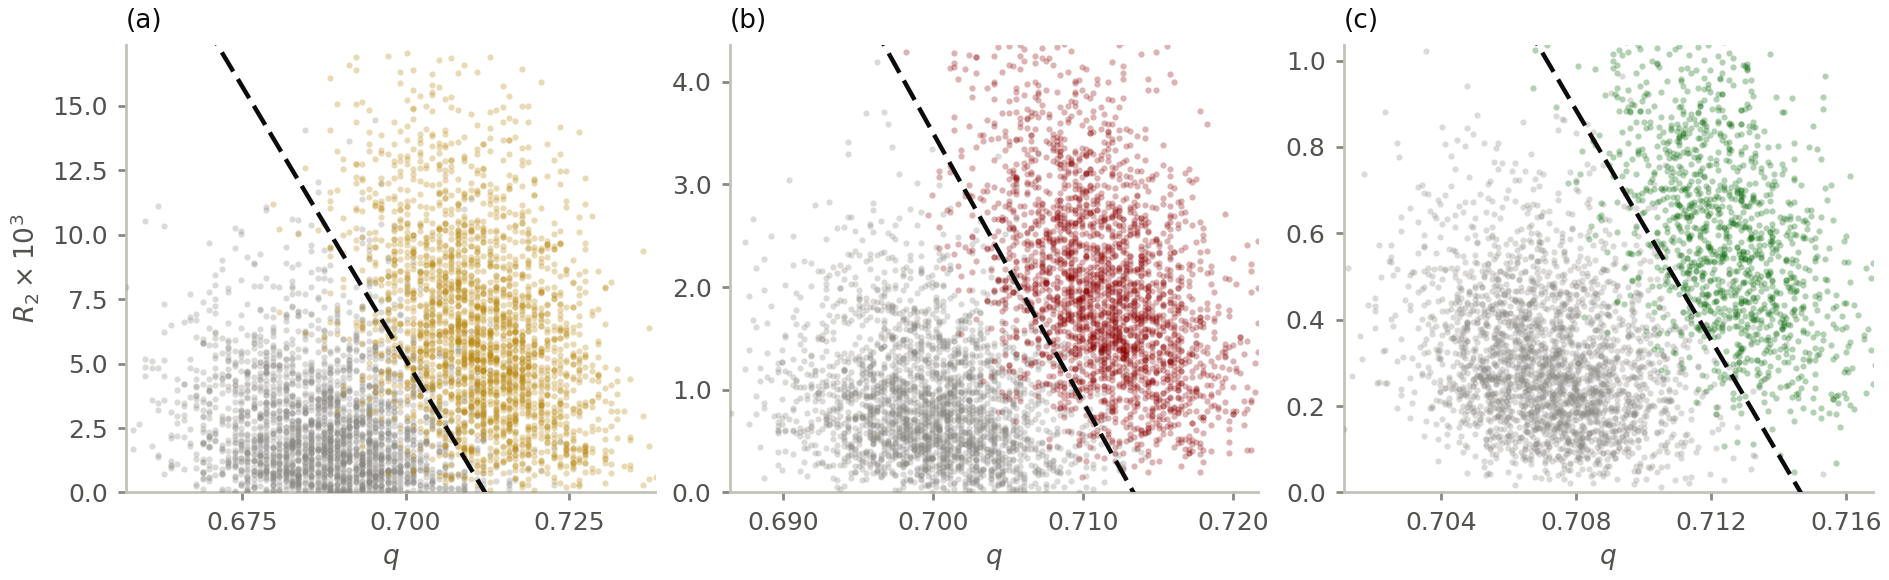

In [3]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 3, figsize=(3.15 * 3, 2.9), dpi=200, layout="constrained", facecolor=BG)
for ax, L, letter in zip(axes, SIZES, "abc"):
    H, q, y = m.microstates("test_pool", L)
    r2 = m.r2_fast(H, q)
    for label, color in ((0, GRAY), (1, COLORS[L])):
        i = np.flatnonzero(y == label)
        if len(i) > 2500:
            i = rng.choice(i, 2500, replace=False)
        ax.scatter(q[i], 1e3 * r2[i], s=5, c=color, alpha=0.30, linewidths=0, zorder=3)

    coef = model[L]["model"]
    (mean_q, mean_R), (std_q, std_R) = coef["mean"], coef["std"]
    qs = np.linspace(*np.quantile(q, (0.001, 0.999)), 200)
    boundary = mean_R + std_R * (-coef["b0"] - coef["bq"] * (qs - mean_q) / std_q) / coef["bR"]
    ax.plot(qs, 1e3 * boundary, color=TEXT, linewidth=1.6, linestyle=(0, (5, 2)), zorder=4)

    ax.set_xlim(qs[0], qs[-1])
    ax.set_ylim(0, 1e3 * np.quantile(r2, 0.995))
    ax.xaxis.set_major_locator(MaxNLocator(4, prune="both"))
    ax.xaxis.set_major_formatter("{x:.3f}")
    ax.yaxis.set_major_formatter("{x:.1f}")
    ax.set_xlabel("$q$", fontsize=9.5, color=LABEL)
    ax.set_title(f"({letter})", loc="left", fontsize=9.5, color=TEXT, pad=6)
    ax.set_facecolor(BG)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["bottom", "left"]].set(color=AXIS, linewidth=1.0)
    ax.tick_params(color=GRAY, labelcolor=LABEL, labelsize=9, length=3, width=1.0)
axes[0].set_ylabel("$R_2 \\times 10^{3}$", fontsize=9.5, color=LABEL)

fig.savefig("../data_repository/figures/fig_qr2_plane.png")
fig.savefig("../data_repository/figures/fig_qr2_plane.pdf")
plt.close(fig)
display(Image("../data_repository/figures/fig_qr2_plane.png"))

#### The model (q, R2) against the network on raw images (Table 6, Appendix B)

In [4]:
network = {L: m.qr2_vs_network(L) for L in SIZES}
m.table(network)

,seeds,n_boot,eps_network,eps_network_spread,eps_network_train,eps_network_validation,ci_qR2_minus_network,fraction_qR2,ci_fraction_qR2
32,"[0, 1, 2, 3, 4]",2000,0.096586,0.000636,0.080439,0.080447,"[0.01634, 0.02713]",0.835401,"[0.7954, 0.876]"
64,"[0, 1, 2, 3, 4]",2000,0.065798,0.001831,0.049923,0.063830,"[0.003638, 0.01594]",0.922824,"[0.873, 0.9703]"
128,"[0, 1, 2, 3, 4]",2000,0.061090,0.008092,0.034457,0.056519,"[-0.009776, 0.006317]",1.019887,"[0.9433, 1.096]"


#### The network and R2 on thinned images (Section 3.6)

In [5]:
network_r2 = {L: m.network_vs_r2(L) for L in SIZES}
m.table(network_r2)

,auc_R2,spearman,auc_network_fixed_R2_20,auc_R2_fixed_network_20
32,0.752566,0.766518,0.697774,0.540428
64,0.807470,0.716575,0.742360,0.577584
128,0.833877,0.623324,0.747963,0.644430
